In [ ]:
import numpy as np
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')



data_path = '/content/drive/MyDrive/dataset/diabetes.csv'

df = pd.read_csv(data_path)

df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


In [ ]:
from sklearn.model_selection import train_test_split
# Prepare features and target variable
X = df[['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']]
y = df['Outcome']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LogisticRegression

# Initialize and train the logistic regression model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)



LogisticRegression(max_iter=1000)

In [ ]:

import pickle

# Save the trained model
with open('diabetes_model.pkl', 'wb') as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [ ]:

from google.colab import files

files.download('diabetes_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
X_test

,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction
668,43,34.0,58.0,190.0,98,0.430
324,21,35.7,75.0,102.5,112,0.148
624,21,30.8,64.0,102.5,108,0.158
690,34,24.6,80.0,102.5,107,0.856
473,50,29.9,90.0,102.5,136,0.210
...,...,...,...,...,...,...
355,49,30.4,88.0,169.5,165,0.302
534,24,33.3,56.0,56.0,77,1.251
344,57,36.8,72.0,102.5,95,0.485
296,29,28.0,70.0,360.0,146,0.337


In [ ]:
# Weights
print(model.coef_)

# Constant / intercept
print(model.intercept_)

[[ 0.04559683  0.09394991 -0.00964773  0.00442035  0.03010364  0.48521205]]
[-9.2358725]


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
# Predict on the test set
y_pred = model.predict(X_test)

# Calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy Score: {accuracy:.4f}')

Accuracy Score: 0.7597


In [ ]:
y_pred

array([0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0])

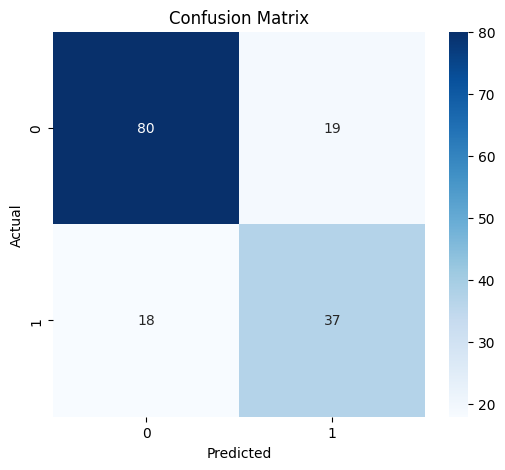

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize the confusion matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()





In [ ]:
21,35.7,75.0,102.5,112,0.148

(21, 35.7, 75.0, 102.5, 112, 0.148)